# When timestamps help CTSM 1.5

Forecast hourly service traffic at the start of a weekend. The five-day history contains weekday traffic. Past timestamps give the model the daily and weekly phase at the forecast origin. Both forecasts disable flip equivariance to isolate the effect of calendar inputs.

**Setup** · Use a Jupyter kernel with PyTorch, NumPy, pandas and Matplotlib.
Start from within the CTSM checkout and place the released CTSM 1.5 weights at
`checkpoints/model.safetensors` relative to the checkout root,
or set `CTSM_CHECKPOINT` to its path before starting Jupyter.

In [1]:
from pathlib import Path
import os
import sys

from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

working_dir = Path.cwd().resolve()
root = next(
    (
        candidate
        for candidate in (working_dir, *working_dir.parents)
        if (candidate / "ctsm_1p5" / "modeling" / "__init__.py").is_file()
    ),
    None,
)
if root is None:
    raise FileNotFoundError("Start the notebook from within the CTSM 1.5 checkout.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from ctsm_1p5.modeling import load_model

checkpoint = Path(
    os.environ.get("CTSM_CHECKPOINT", "checkpoints/model.safetensors")
).expanduser()
if not checkpoint.is_absolute():
    checkpoint = root / checkpoint

model = load_model(checkpoint, flip_equivariance=False)

## Generate hourly service traffic

Weekdays have a business-hours surge. Weekends have a smaller afternoon peak. Each of the 12 series varies its phase, scale, and random noise. The scenario was chosen in a pilot and is scored here on fresh seeds.

In [2]:
HISTORY = 5 * 24
HORIZON = 2 * 24
seeds = range(101, 113)
cutoffs = pd.date_range("2025-04-05", periods=len(seeds), freq="W-SAT")

def make_service_traffic(cutoff, seed):
    rng = np.random.default_rng(seed)
    clock = pd.date_range(
        start=cutoff - pd.Timedelta(hours=HISTORY),
        periods=HISTORY + HORIZON,
        freq="h",
    )
    hour = clock.hour.to_numpy()
    is_weekday = clock.dayofweek.to_numpy() < 5
    phase = rng.uniform(-1.0, 1.0)
    opens = 1 / (1 + np.exp(-1.5 * (hour - 8 - phase)))
    closes = 1 / (1 + np.exp(-1.5 * (hour - 18 - phase)))
    weekend_peak = np.exp(-((hour - 14 - phase) / 6.1) ** 2)
    level = np.where(is_weekday, 15 + 90 * (opens - closes), 12 + 10 * weekend_peak)
    traffic = level * rng.uniform(0.78, 1.22) + rng.normal(0, 2.5, len(clock))
    return pd.Series(traffic.clip(0).astype(np.float32), index=clock)

series = [make_service_traffic(cutoff, seed) for cutoff, seed in zip(cutoffs, seeds)]
past = [sample.iloc[:HISTORY] for sample in series]
target = [sample.iloc[HISTORY:] for sample in series]

## Forecast with and without timestamps

Both calls use the same values, checkpoint, 48-hour horizon, and single-pass decoding. The timestamped call receives the **past** clock only. CTSM extrapolates the future time-of-day and day-of-week features from the last two supplied timestamps.

In [3]:
histories = [sample.to_numpy() for sample in past]
past_clocks = [sample.index.to_numpy() for sample in past]
predictions = {
    "Values only": model.forecast(
        histories, horizon_len=HORIZON, batch_size=4, use_timestamps=False
    ),
    "With timestamps": model.forecast(
        histories, horizon_len=HORIZON, batch_size=4,
        timestamps=past_clocks, use_timestamps=True,
    ),
}

## Compare the forecasts

The plots show the first held-out seed. The table averages over every series. MAE scores the median forecast. Pinball loss scores all 15 predicted quantiles.

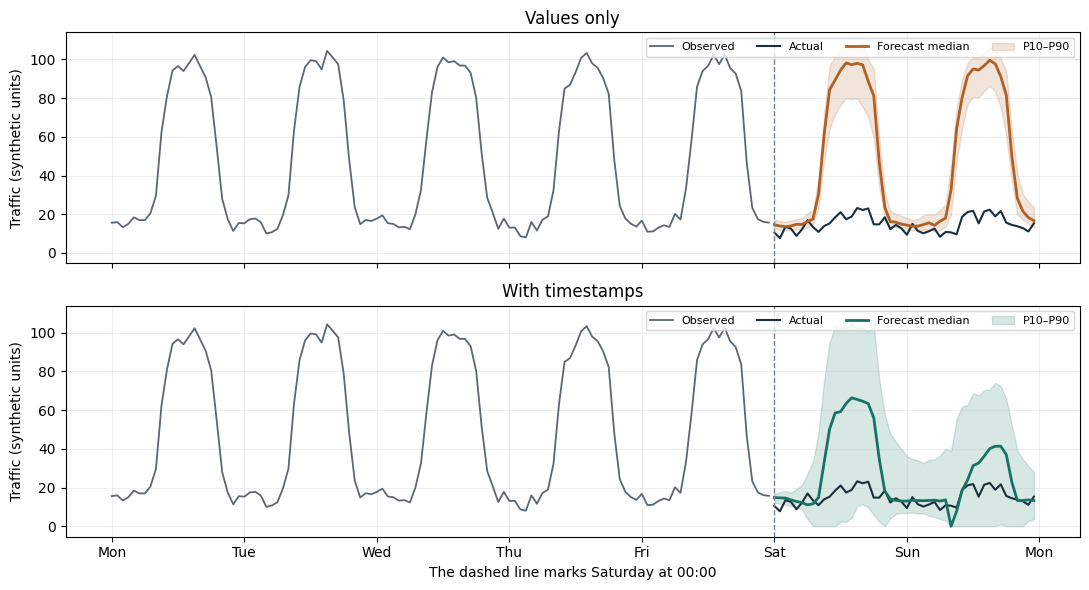

In [4]:
i = 0
observed, actual = past[i], target[i]
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, sharey=True)
colors = {"Values only": "#B16024", "With timestamps": "#167364"}

for ax, (mode, forecasts) in zip(axes, predictions.items()):
    forecast = forecasts[i]["quantiles"]
    color = colors[mode]
    ax.plot(observed.index, observed, color="#596874", lw=1.3, label="Observed")
    ax.plot(actual.index, actual, color="#182F3C", lw=1.5, label="Actual")
    ax.plot(actual.index, forecast["0.5"], color=color, lw=2, label="Forecast median")
    ax.fill_between(
        actual.index, forecast["0.1"], forecast["0.9"],
        color=color, alpha=0.17, label="P10–P90",
    )
    ax.axvline(actual.index[0], color="#718492", linestyle="--", lw=1)
    ax.set(title=mode, ylabel="Traffic (synthetic units)")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right", ncols=4, fontsize=8)
axes[-1].xaxis.set_major_locator(mdates.DayLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a"))
axes[-1].set_xlabel("The dashed line marks Saturday at 00:00")
fig.tight_layout()
plt.show()

In [5]:
actual_values = np.stack([sample.to_numpy() for sample in target])

def score(forecasts):
    keys = sorted(forecasts[0]["quantiles"], key=float)
    levels = np.array([float(key) for key in keys])
    quantiles = np.stack([
        np.column_stack([forecast["quantiles"][key] for key in keys])
        for forecast in forecasts
    ])
    error = actual_values[:, :, None] - quantiles
    pinball = np.maximum(levels * error, (levels - 1) * error)
    median = quantiles[:, :, keys.index("0.5")]
    mae = np.abs(actual_values - median).mean(axis=1)
    return mae, pinball.mean(axis=(1, 2))

errors = {mode: score(forecasts) for mode, forecasts in predictions.items()}
metrics = pd.DataFrame({
    mode: {"Median MAE": mae.mean(), "Pinball loss": pinball.mean()}
    for mode, (mae, pinball) in errors.items()
}).T
display(metrics.round(2))
relative = 1 - metrics.loc["With timestamps"] / metrics.loc["Values only"]
wins = np.count_nonzero(errors["With timestamps"][0] < errors["Values only"][0])
print(f"MAE reduction: {relative['Median MAE']:.1%} ({wins}/{len(series)} series improved)")
print(f"Pinball loss reduction: {relative['Pinball loss']:.1%}")

,Median MAE,Pinball loss
Values only,37.30,14.11
With timestamps,11.25,3.50


MAE reduction: 69.8% (12/12 series improved)
Pinball loss reduction: 75.2%
